# Assignment #9 (demo). Time series analysis

<img src="https://habrastorage.org/webt/ia/m9/zk/iam9zkyzqebnf_okxipihkgjwnw.jpeg" />

**<center>[mlcourse.ai](https://mlcourse.ai) – Open Machine Learning Course** </center><br>

Author: Mariya Mansurova, Analyst & developer in Yandex.Metrics team. Translated by Ivan Zakharov, ML enthusiast. This material is subject to the terms and conditions of the [Creative Commons CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/) license. Free use is permitted for any non-commercial purpose.


**Same assignment as a [Kaggle Notebook](https://www.kaggle.com/kashnitsky/a9-demo-time-series-analysis) + [solution](https://www.kaggle.com/kashnitsky/a9-demo-time-series-analysis-solution).**

**In this assignment, we are using Prophet and ARIMA to analyze the number of views for a Wikipedia [page](https://en.wikipedia.org/wiki/Machine_learning) on Machine Learning.**

**Fill cells marked with "Your code here" and submit your answers to the questions through the [web form](https://docs.google.com/forms/d/1UYQ_WYSpsV3VSlZAzhSN_YXmyjV7YlTP8EYMg8M8SoM/edit).**

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import requests
from plotly import __version__
from plotly import graph_objs as go
from plotly.offline import download_plotlyjs, init_notebook_mode, iplot, plot
from IPython.display import display, IFrame

print(__version__)  # need 1.9.0 or greater
init_notebook_mode(connected=True)

7.1.0


In [2]:
def plotly_df(df, title="", width=800, height=500):
    """Visualize all the dataframe columns as line plots."""
    common_kw = dict(x=df.index, mode="lines")
    data = [go.Scatter(y=df[c], name=c, **common_kw) for c in df.columns]
    layout = dict(title=title)
    fig = dict(data=data, layout=layout)

    # in a Jupyter Notebook, the following should work
    #iplot(fig, show_link=False)

    # in a Jupyter Book, we save a plot offline and then render it with IFrame
    iplot(fig)

## Data preparation

In [3]:
# for Jupyter-book, we copy data from GitHub, locally, to save Internet traffic,
# you can specify the data/ folder from the root of your cloned
# https://github.com/Yorko/mlcourse.ai repo, to save Internet traffic
DATA_PATH = "https://raw.githubusercontent.com/Yorko/mlcourse.ai/main/data/"

In [4]:
df = pd.read_csv(DATA_PATH + "wiki_machine_learning.csv", sep=" ")
df = df[df["count"] != 0]
df.head()


,date,count,lang,page,rank,month,title
81,2015-01-01,1414,en,Machine_learning,8708,201501,Machine_learning
80,2015-01-02,1920,en,Machine_learning,8708,201501,Machine_learning
79,2015-01-03,1338,en,Machine_learning,8708,201501,Machine_learning
78,2015-01-04,1404,en,Machine_learning,8708,201501,Machine_learning
77,2015-01-05,2264,en,Machine_learning,8708,201501,Machine_learning


In [5]:
df.shape

(383, 7)

## Predicting with FB Prophet
We will train on the first 5 months and predict the number of trips for June.

In [6]:
df.date = pd.to_datetime(df.date)

In [7]:
plotly_df(df=df.set_index("date")[["count"]], title="assign9_plot")

In [8]:
from prophet import Prophet

In [9]:
predictions = 30

df = df[["date", "count"]]
df.columns = ["ds", "y"]
df.tail()

,ds,y
382,2016-01-16,1644
381,2016-01-17,1836
376,2016-01-18,2983
375,2016-01-19,3389
372,2016-01-20,3559


**<font color='red'>Question 1:</font>** What is the prediction of the number of views of the wiki page on January 20? Round to the nearest integer.

- 4947
- 3426
- 5229
- 2744

In [10]:
train_df = df[:-predictions].copy()

m = Prophet()
m.fit(train_df)

future = m.make_future_dataframe(periods=predictions)
forecast = m.predict(future)
round(forecast.loc[forecast["ds"] == "2016-01-20", "yhat"].iloc[0])

17:39:37 - cmdstanpy - INFO - Chain [1] start processing


17:39:37 - cmdstanpy - INFO - Chain [1] done processing


3427

Estimate the quality of the prediction with the last 30 points.

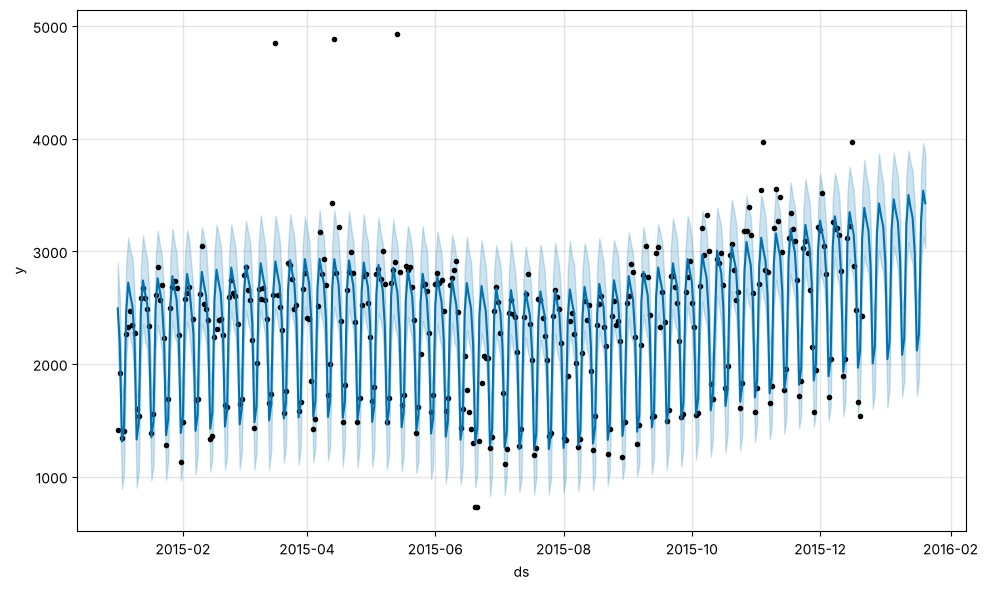

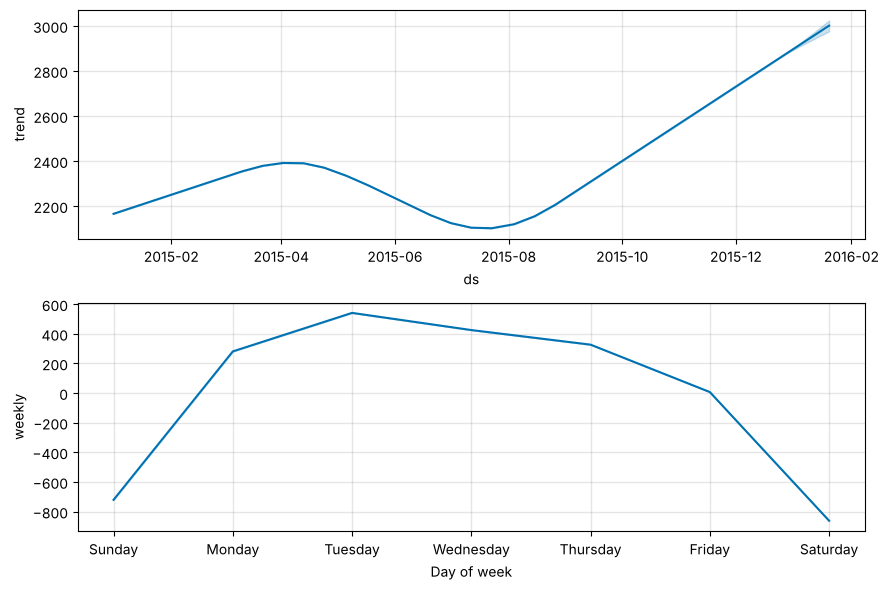

In [11]:
m.plot(forecast)
m.plot_components(forecast);

cmp_df = forecast.set_index("ds")[["yhat", "yhat_lower", "yhat_upper"]].join(df.set_index("ds"))
cmp_df["e"] = cmp_df["y"] - cmp_df["yhat"]
cmp_df["p"] = 100 * cmp_df["e"] / cmp_df["y"]

**<font color='red'>Question 2:</font> What is MAPE equal to?**

- 34.5
- 42.42
- 5.39
- 65.91

In [12]:
round(np.mean(np.abs(cmp_df[-predictions:]["p"])), 2)

np.float64(34.53)

**<font color='red'>Question 3:</font> What is MAE equal to?**

- 355
- 4007
- 600
- 903

In [13]:
round(np.mean(np.abs(cmp_df[-predictions:]["e"])), 2)

np.float64(600.35)

## Predicting with ARIMA

In [14]:
%matplotlib inline
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

plt.rcParams["figure.figsize"] = (15, 10)

**<font color='red'>Question 4:</font> Let's verify the stationarity of the series using the Dickey-Fuller test. Is the series stationary? What is the p-value?**

- Series is stationary, p_value = 0.107
- Series is not stationary, p_value = 0.107
- Series is stationary, p_value = 0.001
- Series is not stationary, p_value = 0.001

Dickey-Fuller test: p=0.107392
Not stationary


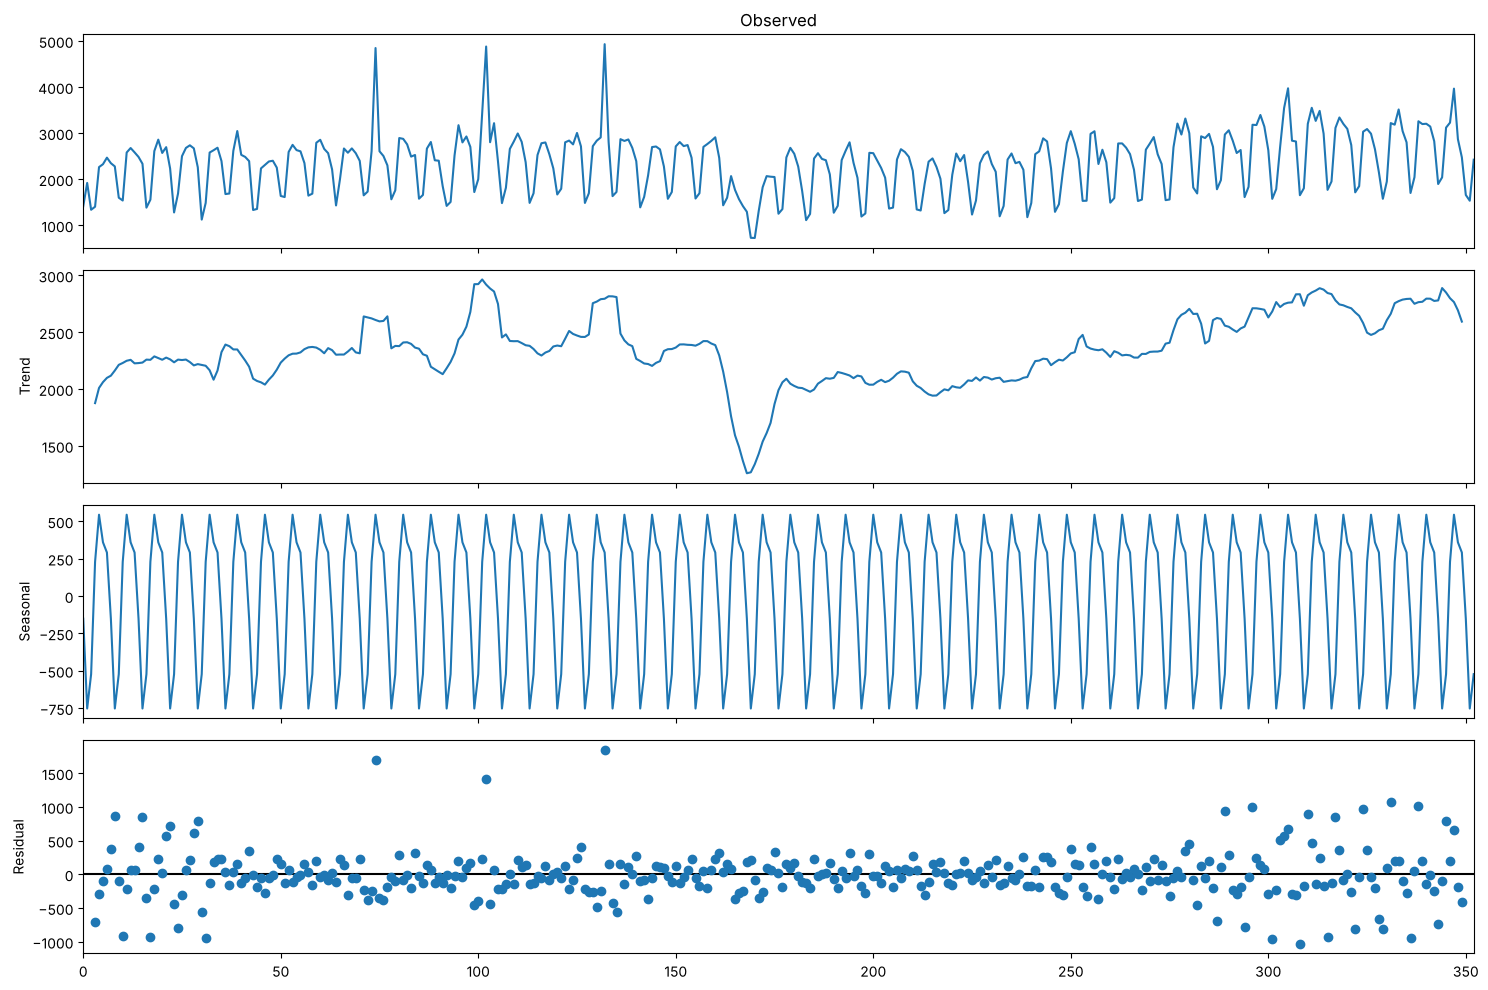

In [15]:
sm.tsa.seasonal_decompose(train_df["y"].values, period=7).plot()
p_value = sm.tsa.stattools.adfuller(train_df["y"])[1]
print("Dickey-Fuller test: p=%f" % p_value)
print("Stationary" if p_value < 0.05 else "Not stationary")

**Next, we turn to the construction of the SARIMAX model (`sm.tsa.statespace.SARIMAX`).<br> <font color='red'>Question 5:</font> What parameters are the best for the model according to the `AIC` criterion?**

- D = 1, d = 0, Q = 0, q = 2, P = 3, p = 1
- D = 2, d = 1, Q = 1, q = 2, P = 3, p = 1
- D = 1, d = 1, Q = 1, q = 2, P = 3, p = 1
- D = 0, d = 0, Q = 0, q = 2, P = 3, p = 1

In [16]:
warnings.simplefilter("ignore")
train_df = train_df.set_index("ds")

options = {
    "D=1, d=0, Q=0, q=2, P=3, p=1": ((1, 0, 2), (3, 1, 0, 7)),
    "D=2, d=1, Q=1, q=2, P=3, p=1": ((1, 1, 2), (3, 2, 1, 7)),
    "D=1, d=1, Q=1, q=2, P=3, p=1": ((1, 1, 2), (3, 1, 1, 7)),
    "D=0, d=0, Q=0, q=2, P=3, p=1": ((1, 0, 2), (3, 0, 0, 7)),
}

aics = {}
for name, (order, seasonal_order) in options.items():
    model = sm.tsa.statespace.SARIMAX(train_df["y"], order=order, seasonal_order=seasonal_order).fit(disp=False)
    aics[name] = model.aic

pd.Series(aics, name="aic").sort_values()

D=2, d=1, Q=1, q=2, P=3, p=1    4989.002315
D=1, d=1, Q=1, q=2, P=3, p=1    5019.555903
D=1, d=0, Q=0, q=2, P=3, p=1    5022.312525
D=0, d=0, Q=0, q=2, P=3, p=1    5183.805369
Name: aic, dtype: float64